# 02 — Security EDA

Exploratory analysis of the prepared tables to surface the attacker, the C2
channel, and the delivery stages. Supports the cybersecurity investigation in
`cybersecurity/investigation.md`.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
packets = pd.read_csv('../data/processed/packets.csv', parse_dates=['time_utc'])
http    = pd.read_csv('../data/processed/http.csv')
dns     = pd.read_csv('../data/processed/dns.csv')
ATTACKER, VICTIM = '45.126.209.4', '10.1.9.101'

## 1. Conversations — who talks to whom

In [2]:
tcp = packets[packets.proto == 'TCP'].copy()
tcp['pair'] = tcp.apply(lambda r: ' <-> '.join(sorted([f"{r.src}:{int(r.sport)}" if pd.notna(r.sport) else r.src,
                                                        f"{r.dst}:{int(r.dport)}" if pd.notna(r.dport) else r.dst])), axis=1)
tcp['pair'].value_counts().head(5).to_frame('packets')

,packets
pair,
10.1.9.101:49723 <-> 45.126.209.4:8808,1199
10.1.9.101:49709 <-> 45.126.209.4:222,338
10.1.9.101:49708 <-> 45.126.209.4:222,11


## 2. Destination port profile
Ports 222 (HTTP staging) and 8808 (C2) are both non-standard.

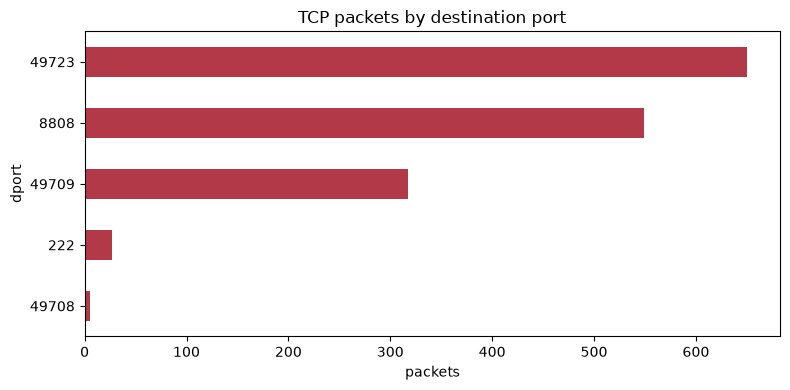

In [3]:
top = packets[packets.proto=='TCP']['dport'].value_counts().head(8).sort_values()
ax = top.plot(kind='barh', figsize=(8,4), color='#B23A48')
ax.set_title('TCP packets by destination port'); ax.set_xlabel('packets'); plt.tight_layout(); plt.show()

## 3. The C2 channel (port 8808)
Most of the capture is the long-lived AsyncRAT channel.

In [4]:
c2 = packets[(packets.dport==8808) | (packets.sport==8808)]
print('C2 packets:', len(c2), '/', len(packets), f'({100*len(c2)/len(packets):.1f}%)')
print('C2 bytes  :', c2.length.sum(), 'B')
print('C2 span   :', round(c2.rel_time.max()-c2.rel_time.min(),1), 's')

C2 packets: 1199 / 1550 (77.4%)
C2 bytes  : 133019 B
C2 span   : 624.7 s


## 4. HTTP delivery stages

In [5]:
http[http.kind=='request'][['rel_time','method','host','uri','dport']]

,rel_time,method,host,uri,dport
0,0.295141,GET,45.126.209.4:222,/xlm.txt,222
2,1.585563,GET,45.126.209.4:222,/mdm.jpg,222


## 5. DNS — C2 resolution

In [6]:
dns[['time_utc','src','qname','is_response']]

,time_utc,src,qname,is_response
0,2024-01-09 17:29:48.927,10.1.9.101,madmrx.duckdns.org,0
1,2024-01-09 17:29:49.262,10.1.9.1,madmrx.duckdns.org,1


### EDA conclusions
- One external peer `45.126.209.4` accounts for all suspicious traffic.
- Two non-standard ports: **222** (two HTTP downloads) and **8808** (AsyncRAT C2,
  the bulk of packets).
- The victim resolves **madmrx.duckdns.org** — dynamic-DNS C2.
- Delivery is two-stage: `/xlm.txt` then `/mdm.jpg`.
